In [1]:
import librosa
import numpy as np
import matplotlib.pyplot as plt
import librosa.display
from IPython.display import Audio

In [2]:
path = "../data/raw/0005.mp3"
y, sr = librosa.load(path, sr=None);
print(f"Sample rate: {sr} Hz | Duration: {len(y)/sr:.1f} s | Samples: {len(y):,}")

Sample rate: 44100 Hz | Duration: 187.2 s | Samples: 8,256,512


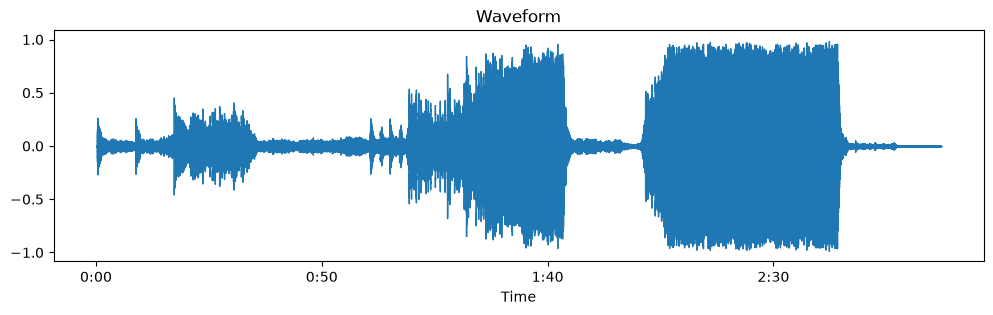

In [3]:
plt.figure(figsize=(12,3))
librosa.display.waveshow(y, sr=sr)
plt.title("Waveform")
plt.show()

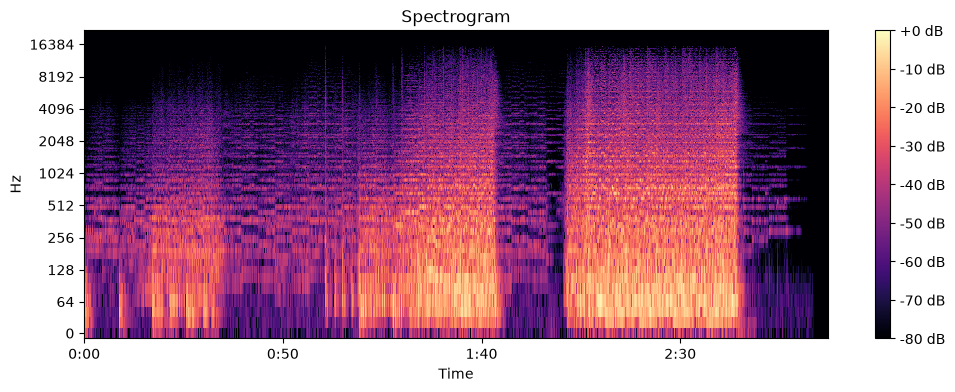

In [4]:
stft = librosa.stft(y, n_fft=2048, hop_length=512) # samples per window = 2048, overlap between two windows = 512
magnitude = np.abs(stft) # output of fourier transform are complex numbers at each frequency which encodes magnitude and phase offset. We only want magnitude
S = librosa.amplitude_to_db(magnitude, ref=np.max) # scale the magnitudes on a log scale to convert them to decibles
plt.figure(figsize=(12, 4))
librosa.display.specshow(S, sr=sr, hop_length=512, x_axis="time", y_axis="log")
plt.colorbar(format="%+2.0f dB")
plt.title("Spectrogram")
plt.show()

In [5]:
Audio(y, rate=sr)

In [6]:
import csv
import os
import re

directory = "../data/raw"
map_path = "../data/id_map.csv"
numbered = re.compile(r"^\d{4}\.\w+$")   # already-renamed files, e.g. 0007.mp3

# continue after the highest existing ID so old IDs never change
existing = [int(f[:4]) for f in os.listdir(directory) if numbered.match(f)]
counter = max(existing, default=-1) + 1

is_new = not os.path.exists(map_path)
with open(map_path, "a", newline="", encoding="utf-8") as m:
    log = csv.writer(m)
    if is_new:
        log.writerow(["track_id", "original_filename"])
    for root, dirs, files in os.walk(directory):
        dirs.clear()                      # don't descend into subfolders
        for filename in sorted(files):
            if numbered.match(filename) or filename.startswith("."):
                continue                  # already renamed, or hidden (.DS_Store)
            ext = os.path.splitext(filename)[1].lower()
            os.rename(os.path.join(root, filename), os.path.join(root, f"{counter:04d}{ext}"))
            log.writerow([counter, filename])   # remember what it used to be called
            counter += 1